# KNN


KNN is trained on raw pixel values which means this model has no way of determing the context around an individual pixel.



In [50]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
import pandas as pd
from pathlib import Path
from PIL import Image

## Build 64x64 splits

Images are downsampled from 224x224 (about 50,000 features) to 64x64 (4,096 features).

In [4]:
DATA_DIR = Path("../data/")
OUT_DIR = (DATA_DIR / "processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)
Size=(224,224)

def load_resized(path, size = Size):
    with Image.open(path) as img:
        return np.asarray(img.convert("L").resize(size), dtype=np.uint8)


def build_split(csv_name, out_name):
    df = pd.read_csv(DATA_DIR/csv_name)
    X = np.stack([load_resized(p, (64,64)) for p in df["Path"]])
    y = df["Labels"].to_numpy()
    np.savez_compressed(OUT_DIR / out_name, X=X, y=y)
    print(out_name, X.shape, X.dtype)



build_split("train.csv", "train_64.npz")
build_split("test.csv", "test_64.npz")
build_split("val.csv", "val_64.npz")


train_64.npz (4728, 64, 64) uint8
test_64.npz (1584, 64, 64) uint8
val_64.npz (701, 64, 64) uint8


In [5]:
DATA_DIR = Path("../data/")
OUT_DIR = (DATA_DIR / "processed")

def load_split(name):
    data = np.load(OUT_DIR / f"{name}.npz", allow_pickle=True)
    return normalize(data["X"]), data["y"]
def normalize(X):
    X = X.astype(np.float32)
    mins = X.min(axis=(1,2), keepdims=True)
    maxs = X.max(axis=(1,2), keepdims=True)
    return (X - mins) / (maxs - mins + 1e-8)

x_train, y_train = load_split("train_64")
x_val, y_val = load_split("val_64")
x_test, y_test = load_split("test_64")

## Extreme K's

In [37]:
knn = KNeighborsClassifier(n_neighbors = 1)

x_train = x_train.reshape(x_train.shape[0], -1)
x_val = x_val.reshape(x_val.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)

knn.fit(x_train, y_train)
print(classification_report(y_train, knn.predict(x_train)))
print(classification_report(y_val, knn.predict(x_val)))
#k = 5 this is the base

              precision    recall  f1-score   support

      glioma       1.00      1.00      1.00      1219
  meningioma       1.00      1.00      1.00      1207
     notumor       1.00      1.00      1.00      1116
   pituitary       1.00      1.00      1.00      1186

    accuracy                           1.00      4728
   macro avg       1.00      1.00      1.00      4728
weighted avg       1.00      1.00      1.00      4728

              precision    recall  f1-score   support

      glioma       0.92      0.91      0.91       181
  meningioma       0.91      0.87      0.89       179
     notumor       0.95      0.95      0.95       165
   pituitary       0.95      1.00      0.98       176

    accuracy                           0.93       701
   macro avg       0.93      0.93      0.93       701
weighted avg       0.93      0.93      0.93       701



In [49]:
knn = KNeighborsClassifier(n_neighbors = 4728)

x_train = x_train.reshape(x_train.shape[0], -1)
x_val = x_val.reshape(x_val.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)

knn.fit(x_train, y_train)
print(classification_report(y_train, knn.predict(x_train)))
print(classification_report(y_val, knn.predict(x_val)))
#k = 5 this is the base

c:\Users\cj816\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\cj816\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\cj816\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

              precision    recall  f1-score   support

      glioma       0.26      1.00      0.41      1219
  meningioma       0.00      0.00      0.00      1207
     notumor       0.00      0.00      0.00      1116
   pituitary       0.00      0.00      0.00      1186

    accuracy                           0.26      4728
   macro avg       0.06      0.25      0.10      4728
weighted avg       0.07      0.26      0.11      4728

              precision    recall  f1-score   support

      glioma       0.26      1.00      0.41       181
  meningioma       0.00      0.00      0.00       179
     notumor       0.00      0.00      0.00       165
   pituitary       0.00      0.00      0.00       176

    accuracy                           0.26       701
   macro avg       0.06      0.25      0.10       701
weighted avg       0.07      0.26      0.11       701



c:\Users\cj816\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\cj816\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\cj816\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

K is a hyperparameter of KNN, that is K a variable that is used to tune the nature of our test.
Above you can see that if K is too small then it will begin to overfit being largely influenced by outliers in the data, and if K is too big then it will begin to underfit instead choosing which ever category is most prevalent in the training set

In [12]:
from sklearn.metrics import f1_score

# Tuning K


In [35]:
ky = list(range(55,85,2))
results = []
for k in ky:
    guess = KNeighborsClassifier(
        n_neighbors = k
    )

    guess.fit(x_train,y_train)
    train_f1 = f1_score(y_train, guess.predict(x_train), average="macro")
    val_f1 = f1_score(y_val, guess.predict(x_val), average="macro")

    results.append({
            "k": k,
            "train_f1": round(train_f1, 3),
            "val_f1": round(val_f1, 3),
            "gap": round(train_f1 - val_f1, 3),
    })
results_df = pd.DataFrame(results).sort_values("val_f1", ascending=False)
results_df  

,k,train_f1,val_f1,gap
0,55,0.715,0.726,-0.011
5,65,0.707,0.718,-0.012
3,61,0.709,0.715,-0.006
4,63,0.706,0.713,-0.007
1,57,0.714,0.713,0.000
6,67,0.705,0.709,-0.004
2,59,0.710,0.706,0.004
7,69,0.703,0.705,-0.002
8,71,0.701,0.704,-0.004
9,73,0.699,0.702,-0.004


# Final mode

K was chosen to be 57 as it fits within traditional guesses of sqrt(n) where n is the size of training data. It was chosen as it displays the least amount of loss between training and validation. Final model is evaluated on validation and then once on test. Settings were not changed after seeing the test score.

In [47]:
knn = KNeighborsClassifier(n_neighbors = 57)

x_train = x_train.reshape(x_train.shape[0], -1)
x_val = x_val.reshape(x_val.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)

knn.fit(x_train, y_train)
print(classification_report(y_val, knn.predict(x_val)))
print(classification_report(y_test, knn.predict(x_test)))

              precision    recall  f1-score   support

      glioma       0.58      0.85      0.69       181
  meningioma       0.74      0.37      0.50       179
     notumor       0.86      0.75      0.80       165
   pituitary       0.81      0.93      0.87       176

    accuracy                           0.72       701
   macro avg       0.75      0.73      0.71       701
weighted avg       0.74      0.72      0.71       701

              precision    recall  f1-score   support

      glioma       0.50      0.73      0.59       386
  meningioma       0.68      0.20      0.31       398
     notumor       0.75      0.76      0.75       400
   pituitary       0.72      0.89      0.79       400

    accuracy                           0.64      1584
   macro avg       0.66      0.64      0.61      1584
weighted avg       0.66      0.64      0.61      1584



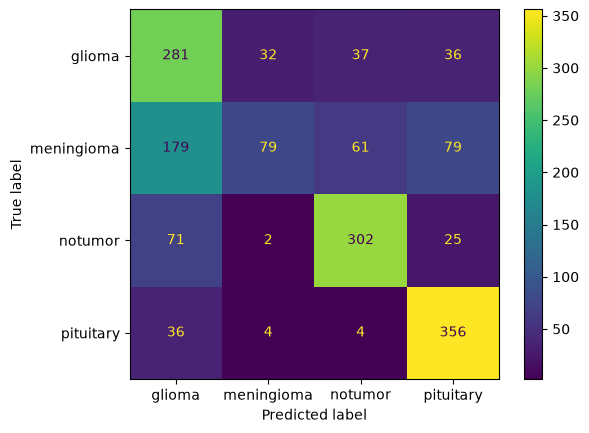

In [48]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print(ConfusionMatrixDisplay.from_predictions(y_test, knn.predict(x_test)))